# Deep Armocromia RGB-M — Dataset Preparation, EDA & Preprocessing

Notebook ini berhenti **tepat sebelum training model**.

## Tujuan
1. Menggunakan **Private Kaggle Dataset hasil ekstraksi** jika sudah tersedia → **tanpa password dan tanpa unzip ulang**.
2. Jika baru pertama kali dan hanya tersedia `RGB-M.zip` terenkripsi → ekstrak **satu kali** ke `/kaggle/working/deep_armocromia_prepared`.
3. Audit anotasi, label, split, file gambar, corrupt image, duplicate/leakage, resolusi, dan kualitas masking.
4. Membuat `train / validation / test` dengan official test tetap untouched.
5. Membuat preprocessing, `Dataset`, `DataLoader`, dan sanity check.
6. Menyimpan split manifest + mapping kelas.
7. Berhenti sebelum EfficientNet/training.

> **Penting:** selama notebook ini dijalankan, gunakan **Accelerator = None**. GPU baru dinyalakan di notebook/session training.

---

## Workflow penggunaan

### Pertama kali
Private dataset lama (berisi `RGB-M.zip`) → notebook ini → masukkan password sekali → extract → Save Version dengan output → **Create Dataset dari Notebook Output** dan set **Private**.

Output yang perlu dijadikan dataset baru:
`/kaggle/working/deep_armocromia_prepared/`

### Session berikutnya
Attach dataset hasil ekstraksi tersebut. Notebook akan mendeteksinya otomatis dan **melewati seluruh proses password/extraction**.

In [1]:
# ============================================================
# 1. IMPORT LIBRARY & REPRODUCIBILITY
# ============================================================

import os
import sys
import json
import math
import random
import shutil
import hashlib
import subprocess
import warnings
from pathlib import Path
from getpass import getpass

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image, ImageFile
from sklearn.model_selection import train_test_split

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

ImageFile.LOAD_TRUNCATED_IMAGES = False

print("Python       :", sys.version.split()[0])
print("Kaggle input :", Path("/kaggle/input").exists())
print("Setup selesai.")

Python       : 3.13.15
Kaggle input : True
Setup selesai.


## 2. Deteksi mode dataset

Notebook memprioritaskan **dataset RGB-M yang sudah diekstrak**.

Kriteria prepared dataset:
- memiliki `annotations.csv`;
- pada folder yang sama terdapat folder `RGB-M/`.

Jika tidak ditemukan, notebook mencari source dataset lama yang memiliki:
- `annotations.csv`;
- `RGB-M.zip`.

In [2]:
# ============================================================
# 2. AUTO-DETECT PREPARED DATASET / ENCRYPTED SOURCE DATASET
# ============================================================

KAGGLE_INPUT = Path("/kaggle/input")
WORK_PREPARED_ROOT = Path("/kaggle/working/deep_armocromia_prepared")

assert KAGGLE_INPUT.exists(), "/kaggle/input tidak ditemukan."

annotation_candidates = list(KAGGLE_INPUT.rglob("annotations.csv"))

print(f"annotations.csv ditemukan: {len(annotation_candidates)}")
for i, p in enumerate(annotation_candidates):
    print(f"[{i}] {p}")

# --- Prioritas 1: prepared extracted dataset ---
prepared_matches = []
for ann in annotation_candidates:
    root = ann.parent
    if (root / "RGB-M").is_dir():
        prepared_matches.append((root, ann))

# --- Prioritas 2: source dataset dengan encrypted RGB-M.zip ---
source_matches = []
for ann in annotation_candidates:
    root = ann.parent
    if (root / "RGB-M.zip").is_file():
        source_matches.append((root, ann, root / "RGB-M.zip"))

if prepared_matches:
    MODE = "PREPARED_INPUT"
    DATA_ROOT, ANNOTATION_PATH = prepared_matches[0]
    RGBM_ZIP = None

    print("\n✅ MODE: PREPARED_INPUT")
    print("Dataset sudah diekstrak.")
    print("Password/extraction TIDAK diperlukan.")

elif source_matches:
    MODE = "ENCRYPTED_SOURCE"
    SOURCE_ROOT, ANNOTATION_PATH, RGBM_ZIP = source_matches[0]
    DATA_ROOT = WORK_PREPARED_ROOT

    print("\n⚠️ MODE: ENCRYPTED_SOURCE")
    print("Prepared dataset belum ditemukan.")
    print("RGB-M akan diekstrak satu kali ke /kaggle/working.")

else:
    raise FileNotFoundError(
        "Tidak ditemukan prepared RGB-M dataset maupun source RGB-M.zip. "
        "Pastikan private dataset Deep Armocromia sudah di-attach."
    )

print("\nMODE            :", MODE)
print("ANNOTATION_PATH :", ANNOTATION_PATH)
print("DATA_ROOT       :", DATA_ROOT)
if RGBM_ZIP is not None:
    print("RGBM_ZIP        :", RGBM_ZIP)

annotations.csv ditemukan: 1
[0] /kaggle/input/datasets/fatihitsbatulhaq/deep-armocromia/Deep Armocromia/release/annotations.csv

⚠️ MODE: ENCRYPTED_SOURCE
Prepared dataset belum ditemukan.
RGB-M akan diekstrak satu kali ke /kaggle/working.

MODE            : ENCRYPTED_SOURCE
ANNOTATION_PATH : /kaggle/input/datasets/fatihitsbatulhaq/deep-armocromia/Deep Armocromia/release/annotations.csv
DATA_ROOT       : /kaggle/working/deep_armocromia_prepared
RGBM_ZIP        : /kaggle/input/datasets/fatihitsbatulhaq/deep-armocromia/Deep Armocromia/release/RGB-M.zip


In [3]:
# ============================================================
# 3. LOAD ANNOTATIONS & KONFIGURASI KOLOM
# ============================================================

df = pd.read_csv(ANNOTATION_PATH)

print("Shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

# Kolom resmi yang digunakan pada pipeline ini
SEASON_COL = "class"
SUBCLASS_COL = "sub_class"
PARTITION_COL = "partition"
MASKED_PATH_COL = "path_rgb_masked"

required_cols = [
    SEASON_COL,
    SUBCLASS_COL,
    PARTITION_COL,
    MASKED_PATH_COL,
]

missing_cols = [c for c in required_cols if c not in df.columns]
assert not missing_cols, f"Kolom wajib tidak ditemukan: {missing_cols}"

# Standardisasi teks tanpa mengubah makna label
for col in [SEASON_COL, SUBCLASS_COL, PARTITION_COL]:
    df[col] = (
        df[col]
        .astype(str)
        .str.strip()
        .str.lower()
    )

df["joint_label"] = df[SEASON_COL] + "_" + df[SUBCLASS_COL]

EXPECTED_IMAGES = len(df)

display(df.head())

print("\nTotal annotation:", EXPECTED_IMAGES)

Shape: (4920, 7)

Columns:
['class', 'sub_class', 'partition', 'celeba', 'path_rgb_original', 'path_rgb_masked', 'path_mask']


,class,sub_class,partition,celeba,path_rgb_original,path_rgb_masked,path_mask,joint_label
0,autunno,deep,train,True,RGB/train/autunno/deep/10306.jpg,RGB-M/train/autunno/deep/10306.png,BM/train/autunno/deep/10306.png,autunno_deep
1,autunno,deep,train,True,RGB/train/autunno/deep/10411.jpg,RGB-M/train/autunno/deep/10411.png,BM/train/autunno/deep/10411.png,autunno_deep
2,autunno,deep,train,True,RGB/train/autunno/deep/10552.jpg,RGB-M/train/autunno/deep/10552.png,BM/train/autunno/deep/10552.png,autunno_deep
3,autunno,deep,train,True,RGB/train/autunno/deep/11174.jpg,RGB-M/train/autunno/deep/11174.png,BM/train/autunno/deep/11174.png,autunno_deep
4,autunno,deep,train,True,RGB/train/autunno/deep/11199.jpg,RGB-M/train/autunno/deep/11199.png,BM/train/autunno/deep/11199.png,autunno_deep



Total annotation: 4920


## 4. Extraction satu kali

Cell ini **hanya bekerja pada mode `ENCRYPTED_SOURCE`**.

- Jika folder RGB-M sudah lengkap di session yang sama → extraction dilewati.
- Jika prepared private dataset sudah di-attach → cell juga dilewati.
- Password tidak ditulis ke notebook.
- Jika Anda menyimpan password sebagai Kaggle Secret bernama `DEEP_ARMO_PASSWORD`, notebook akan mencobanya terlebih dahulu. Jika tidak ada, notebook memakai `getpass()`.

### Setelah first-run berhasil
Simpan `/kaggle/working/deep_armocromia_prepared` sebagai **Private Dataset dari Notebook Output**.  
Pada session berikutnya attach dataset baru tersebut; extraction tidak dijalankan lagi.

In [4]:
# ============================================================
# 4. RGB-M EXTRACTION — KAGGLE SECRET (BATCH-SAFE)
# ============================================================
#
# Sebelum menjalankan Save & Run All:
# Kaggle -> Add-ons / Secrets
# buat secret:
#     Name  : DEEP_ARMO_PASSWORD
#     Value : password resmi RGB-M.zip
# lalu aktifkan akses secret untuk notebook ini.
#
# Tidak ada getpass() pada cell ini agar background/batch run
# tidak berhenti menunggu input manual.

IMAGE_EXTENSIONS = {".png", ".jpg", ".jpeg"}

def count_images(root: Path) -> int:
    if not root.exists():
        return 0
    return sum(
        1
        for p in root.rglob("*")
        if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS
    )

if MODE == "PREPARED_INPUT":
    RGBM_ROOT = DATA_ROOT / "RGB-M"
    current_count = count_images(RGBM_ROOT)

    print("✅ Prepared RGB-M digunakan langsung.")
    print(f"Jumlah image: {current_count}")

else:
    WORK_PREPARED_ROOT.mkdir(parents=True, exist_ok=True)
    RGBM_ROOT = WORK_PREPARED_ROOT / "RGB-M"

    current_count = count_images(RGBM_ROOT)
    print(f"Gambar RGB-M saat ini: {current_count}/{EXPECTED_IMAGES}")

    if current_count == EXPECTED_IMAGES:
        print("✅ RGB-M sudah lengkap pada session ini. Extraction dilewati.")

    else:
        # Wajib Kaggle Secret agar Save & Run All bisa berjalan tanpa input manual
        from kaggle_secrets import UserSecretsClient

        try:
            secret_client = UserSecretsClient()
            PASSWORD = secret_client.get_secret("DEEP_ARMO_PASSWORD")
        except Exception as e:
            raise RuntimeError(
                "Kaggle Secret 'DEEP_ARMO_PASSWORD' belum tersedia/diizinkan. "
                "Tambahkan secret terlebih dahulu sebelum Save & Run All."
            ) from e

        if not PASSWORD:
            raise RuntimeError(
                "Kaggle Secret 'DEEP_ARMO_PASSWORD' kosong. "
                "Isi dengan password resmi RGB-M.zip."
            )

        print("🔐 Password berhasil dibaca dari Kaggle Secret.")
        print("Mengekstrak RGB-M...")

        unzip_path = shutil.which("unzip")

        if unzip_path:
            result = subprocess.run(
                [
                    unzip_path,
                    "-n",              # jangan overwrite file yang sudah ada
                    "-P", PASSWORD,
                    str(RGBM_ZIP),
                    "-d", str(WORK_PREPARED_ROOT),
                ],
                stdout=subprocess.DEVNULL,
                stderr=subprocess.PIPE,
                text=True,
            )

            # unzip dapat mengembalikan 1 untuk warning non-fatal.
            if result.returncode not in (0, 1):
                raise RuntimeError(
                    "Extraction gagal.\n"
                    + result.stderr[-3000:]
                )
        else:
            # Fallback hanya jika binary unzip tidak tersedia
            import zipfile
            with zipfile.ZipFile(RGBM_ZIP, "r") as z:
                z.extractall(
                    WORK_PREPARED_ROOT,
                    pwd=PASSWORD.encode("utf-8")
                )

        # Jangan simpan password lebih lama dari yang diperlukan
        del PASSWORD

        final_count = count_images(RGBM_ROOT)

        print(f"Jumlah image setelah extraction: {final_count}")

        assert final_count == EXPECTED_IMAGES, (
            f"Extraction belum lengkap. Expected {EXPECTED_IMAGES}, "
            f"tetapi ditemukan {final_count}. "
            "Jika session sempat terputus, rerun; file yang sudah ada akan dilewati."
        )

        print("✅ Extraction RGB-M selesai.")

    # Copy annotations agar output prepared dataset mandiri
    prepared_annotation = WORK_PREPARED_ROOT / "annotations.csv"
    if not prepared_annotation.exists():
        shutil.copy2(ANNOTATION_PATH, prepared_annotation)

    DATA_ROOT = WORK_PREPARED_ROOT
    ANNOTATION_PATH = prepared_annotation

print("\nDATA_ROOT final :", DATA_ROOT)
print("RGBM_ROOT       :", RGBM_ROOT)
print("Image count     :", count_images(RGBM_ROOT))

Gambar RGB-M saat ini: 0/4920
🔐 Password berhasil dibaca dari Kaggle Secret.
Mengekstrak RGB-M...
Jumlah image setelah extraction: 4920
✅ Extraction RGB-M selesai.

DATA_ROOT final : /kaggle/working/deep_armocromia_prepared
RGBM_ROOT       : /kaggle/working/deep_armocromia_prepared/RGB-M
Image count     : 4920


### First-run only: membuat Private Dataset hasil extraction

Setelah notebook **first-run** selesai dan semua readiness check PASS:

1. Klik **Save Version** dan pastikan notebook output tersimpan.
2. Dari output notebook, buat dataset baru.
3. Pilih folder:
   `/kaggle/working/deep_armocromia_prepared/`
4. Set visibility **Private**.
5. Session berikutnya attach dataset baru tersebut.
6. Notebook akan otomatis masuk `PREPARED_INPUT` dan tidak meminta password lagi.

Anda **tidak perlu upload ulang dari laptop**.

In [5]:
# ============================================================
# 5. BASIC ANNOTATION AUDIT
# ============================================================

print("=" * 70)
print("ANNOTATION AUDIT")
print("=" * 70)

print("Total rows         :", len(df))
print("Missing values     :", int(df[required_cols].isna().sum().sum()))
print("Duplicated rows    :", int(df.duplicated().sum()))
print("Season classes     :", df[SEASON_COL].nunique())
print("Subclass names     :", df[SUBCLASS_COL].nunique())
print("Joint classes      :", df["joint_label"].nunique())

print("\nSeason distribution:")
display(df[SEASON_COL].value_counts().sort_index().to_frame("count"))

print("\n12 joint classes:")
joint_counts = df["joint_label"].value_counts().sort_index()
display(joint_counts.to_frame("count"))

print("\nOfficial partition:")
partition_counts = df[PARTITION_COL].value_counts()
display(partition_counts.to_frame("count"))

assert df[SEASON_COL].nunique() == 4, "Jumlah season bukan 4."
assert df["joint_label"].nunique() == 12, "Jumlah joint class bukan 12."
assert df[required_cols].isna().sum().sum() == 0, "Ada missing value pada kolom wajib."

print("✅ Audit label dasar PASS.")

ANNOTATION AUDIT
Total rows         : 4920
Missing values     : 0
Duplicated rows    : 0
Season classes     : 4
Subclass names     : 6
Joint classes      : 12

Season distribution:


,count
class,
autunno,1305
estate,1129
inverno,1305
primavera,1181



12 joint classes:


,count
joint_label,
autunno_deep,557
autunno_soft,391
autunno_warm,357
estate_cool,329
estate_light,382
estate_soft,418
inverno_bright,329
inverno_cool,434
inverno_deep,542



Official partition:


,count
partition,
train,4008
test,912


✅ Audit label dasar PASS.


In [6]:
# ============================================================
# 6. CROSS-TAB & CLASS IMBALANCE
# ============================================================

season_subclass = pd.crosstab(
    df[SEASON_COL],
    df[SUBCLASS_COL]
)

print("Season x subclass:")
display(season_subclass)

joint_counts_desc = df["joint_label"].value_counts()

largest_class = joint_counts_desc.idxmax()
smallest_class = joint_counts_desc.idxmin()
largest_count = int(joint_counts_desc.max())
smallest_count = int(joint_counts_desc.min())
imbalance_ratio = largest_count / smallest_count

print(f"Kelas terbesar : {largest_class} ({largest_count})")
print(f"Kelas terkecil : {smallest_class} ({smallest_count})")
print(f"Imbalance ratio: {imbalance_ratio:.2f}x")

partition_joint = pd.crosstab(
    df["joint_label"],
    df[PARTITION_COL]
)

print("\nDistribusi class per official partition:")
display(partition_joint)

Season x subclass:


sub_class,bright,cool,deep,light,soft,warm
class,,,,,,
autunno,0,0,557,0,391,357
estate,0,329,0,382,418,0
inverno,329,434,542,0,0,0
primavera,357,0,0,395,0,429


Kelas terbesar : autunno_deep (557)
Kelas terkecil : estate_cool (329)
Imbalance ratio: 1.69x

Distribusi class per official partition:


partition,test,train
joint_label,,
autunno_deep,112,445
autunno_soft,73,318
autunno_warm,74,283
estate_cool,53,276
estate_light,70,312
estate_soft,63,355
inverno_bright,58,271
inverno_cool,89,345
inverno_deep,117,425


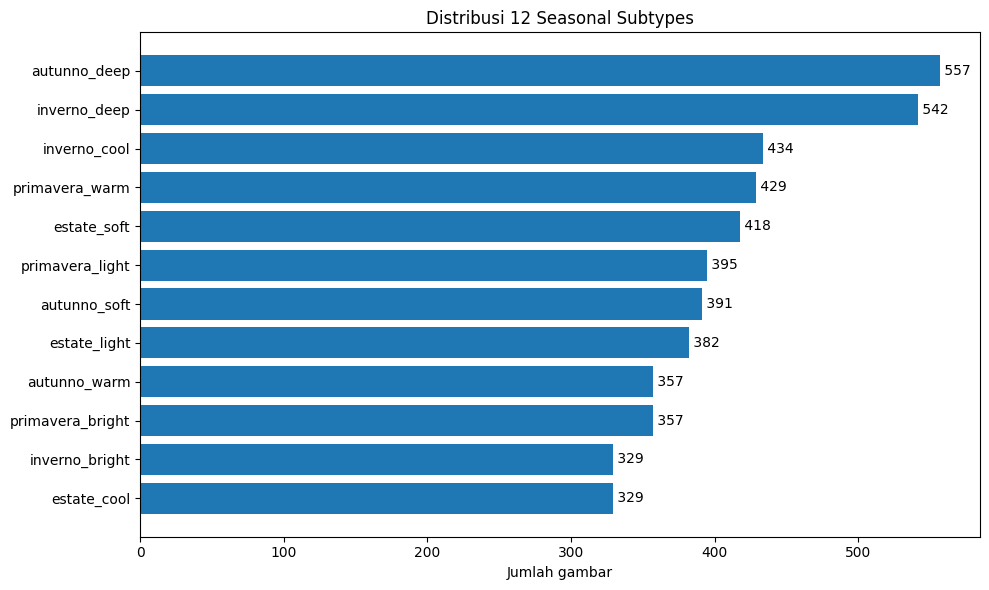

In [7]:
# ============================================================
# 7. VISUALISASI DISTRIBUSI
# ============================================================

fig, ax = plt.subplots(figsize=(10, 6))

plot_counts = (
    df["joint_label"]
    .value_counts()
    .sort_values()
)

ax.barh(plot_counts.index, plot_counts.values)
ax.set_title("Distribusi 12 Seasonal Subtypes")
ax.set_xlabel("Jumlah gambar")

for i, v in enumerate(plot_counts.values):
    ax.text(v, i, f" {v}", va="center")

plt.tight_layout()
plt.show()

In [8]:
# ============================================================
# 8. PATH RESOLVER
# ============================================================

def resolve_image_path(relative_path):
    p = Path(str(relative_path).replace("\\", "/").strip())

    candidates = [
        DATA_ROOT / p,
        DATA_ROOT / "RGB-M" / p,
        DATA_ROOT / "release" / p,
    ]

    # Jika CSV sudah mengandung prefix RGB-M/
    if "RGB-M" in p.parts:
        idx = p.parts.index("RGB-M")
        after_rgbm = Path(*p.parts[idx + 1:])
        candidates.append(DATA_ROOT / "RGB-M" / after_rgbm)

    for candidate in candidates:
        if candidate.exists():
            return candidate

    return None

df["resolved_path"] = df[MASKED_PATH_COL].apply(resolve_image_path)

missing_path_count = int(df["resolved_path"].isna().sum())

print("Total image :", len(df))
print("Path valid  :", len(df) - missing_path_count)
print("Path missing:", missing_path_count)

if missing_path_count:
    print("\nContoh missing path:")
    display(
        df.loc[
            df["resolved_path"].isna(),
            [MASKED_PATH_COL, "joint_label", PARTITION_COL]
        ].head(20)
    )

assert missing_path_count == 0, (
    "Masih ada path missing. Jangan lanjut ke training."
)

print("✅ Seluruh image path valid.")

Total image : 4920
Path valid  : 4920
Path missing: 0
✅ Seluruh image path valid.


In [9]:
# ============================================================
# 9. CORRUPT IMAGE CHECK + IMAGE PROPERTIES
# ============================================================

corrupt_records = []
image_properties = []

for i, row in df.iterrows():
    path = row["resolved_path"]

    try:
        with Image.open(path) as img:
            # Simpan properti terlebih dahulu
            image_properties.append({
                "index": i,
                "width": img.width,
                "height": img.height,
                "mode": img.mode,
            })

            # verify() memeriksa integritas file
            img.verify()

    except Exception as e:
        corrupt_records.append({
            "index": i,
            "path": str(path),
            "error": str(e),
        })

corrupt_df = pd.DataFrame(corrupt_records)
image_info_df = pd.DataFrame(image_properties)

print("Corrupt images:", len(corrupt_records))

if len(corrupt_records):
    display(corrupt_df.head(20))

print("\nImage modes:")
display(image_info_df["mode"].value_counts().to_frame("count"))

print("\nResolusi terbanyak:")
display(
    image_info_df
    .value_counts(["width", "height"])
    .head(20)
    .to_frame("count")
)

print("\nStatistik dimensi:")
display(image_info_df[["width", "height"]].describe())

assert len(corrupt_records) == 0, (
    "Ada corrupt image. Perbaiki sebelum training."
)

print("✅ Tidak ada corrupt image.")

Corrupt images: 0

Image modes:


,count
mode,
RGB,4920



Resolusi terbanyak:


,,count
width,height,
512,512,2981
413,489,2
482,618,2
522,376,2
617,674,2
412,542,2
512,479,2
585,731,2
620,848,1



Statistik dimensi:


,width,height
count,4920.000000,4920.000000
mean,534.065650,574.292886
std,211.986499,263.275514
min,45.000000,110.000000
25%,512.000000,512.000000
50%,512.000000,512.000000
75%,512.000000,512.000000
max,2903.000000,3725.000000


✅ Tidak ada corrupt image.


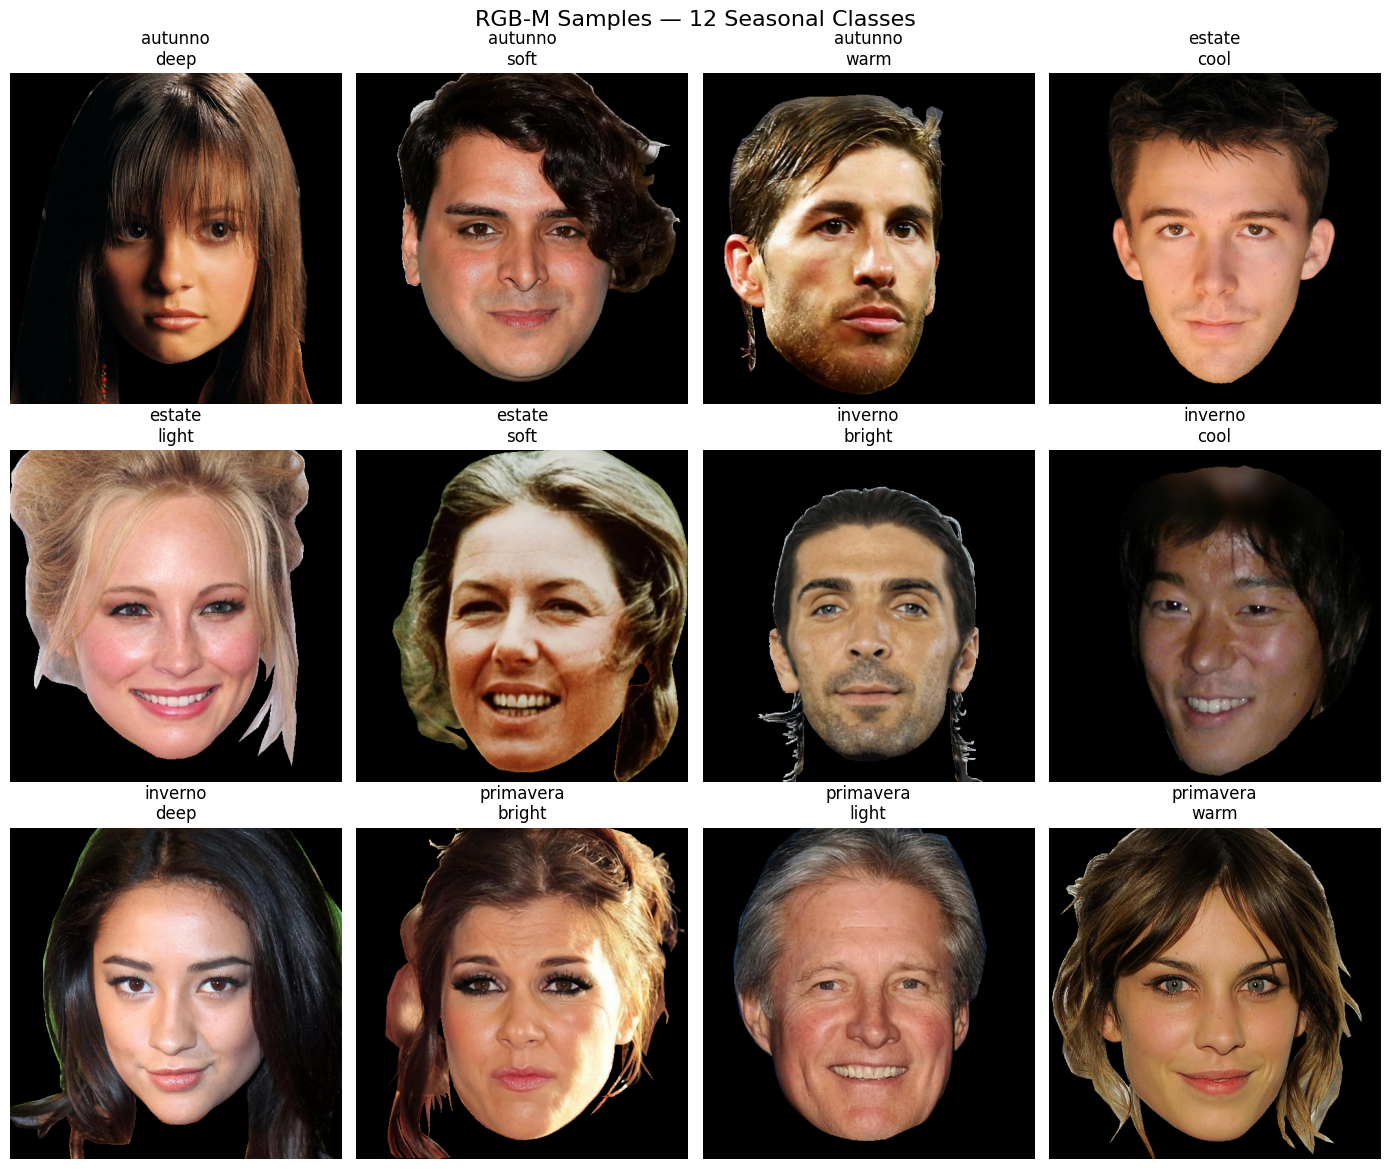

In [10]:
# ============================================================
# 10. SAMPLE GALLERY — 12 CLASSES
# ============================================================

classes = sorted(df["joint_label"].unique())

fig, axes = plt.subplots(3, 4, figsize=(14, 12))
axes = axes.flatten()

for ax, label in zip(axes, classes):
    row = (
        df[df["joint_label"] == label]
        .sample(1, random_state=SEED)
        .iloc[0]
    )

    img = Image.open(row["resolved_path"]).convert("RGB")

    ax.imshow(img)
    ax.set_title(label.replace("_", "\n"))
    ax.axis("off")

plt.suptitle("RGB-M Samples — 12 Seasonal Classes", fontsize=16)
plt.tight_layout()
plt.show()

## 11. Mask-quality audit

Karena kita memakai **RGB-M**, kita perlu memastikan model tidak memperoleh shortcut hanya dari **luas area mask**.

Agar EDA tetap ringan, audit ini mengambil maksimal **50 gambar per class** dan mengecilkannya ke `128×128` hanya untuk analisis statistik.  
Ini **tidak mengubah data training asli**.

visible_ratio                                \
                          mean       std       min       max   
joint_label                                                    
autunno_deep          0.578014  0.164198  0.241516  0.896240   
autunno_soft          0.643208  0.131765  0.451660  0.892639   
autunno_warm          0.639449  0.115843  0.401550  0.895447   
estate_cool           0.665665  0.134486  0.342346  0.892761   
estate_light          0.657821  0.139909  0.260071  0.940186   
estate_soft           0.694133  0.122746  0.391541  0.899292   
inverno_bright        0.600148  0.120058  0.364502  0.859802   
inverno_cool          0.601082  0.119123  0.336243  0.794067   
inverno_deep          0.584603  0.146619  0.220825  0.850464   
primavera_bright      0.667915  0.100472  0.457275  0.861633   
primavera_light       0.680656  0.117018  0.413696  0.933594   
primavera_warm        0.654375  0.126111  0.361328  0.909241   

                 visible_brightness                                    
                               mean        std        min         max  
joint_label                                                            
autunno_deep              86.238530  20.619131  43.190997  126.473491  
autunno_soft             108.343686  18.778161  59.321933  147.913458  
autunno_warm              96.465227  19.682298  56.296324  145.856162  
estate_cool              117.663650  24.469489  75.942565  202.313187  
estate_light             133.601229  20.004244  92.427047  188.350376  
estate_soft              121.745254  24.638709  80.284074  178.355257  
inverno_bright            97.309840  21.326025  64.264628  150.685979  
inverno_cool             101.275164  24.539923  60.722631  190.513886  
inverno_deep              86.778989  19.279685  52.300048  138.537258  
primavera_bright          96.880499  22.320835  49.761870  147.788102  
primavera_light          131.227263  19.792151  97.577874  176.388847  
primavera_warm           109.833254  21.446220  40.774534  144.463393

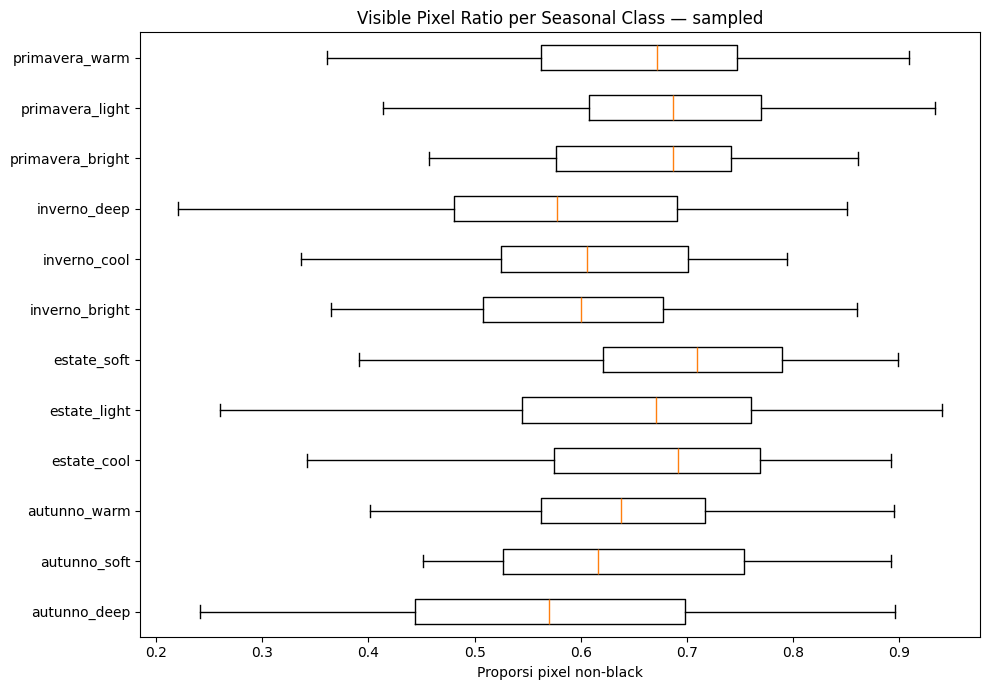

In [11]:
# ============================================================
# 11. SAMPLED MASK / VISIBLE PIXEL RATIO AUDIT
# ============================================================

MASK_AUDIT_PER_CLASS = 50
MASK_AUDIT_SIZE = (128, 128)

audit_rows = []

for label in sorted(df["joint_label"].unique()):
    subset = df[df["joint_label"] == label]

    n = min(MASK_AUDIT_PER_CLASS, len(subset))
    sample = subset.sample(n=n, random_state=SEED)

    for _, row in sample.iterrows():
        img = (
            Image.open(row["resolved_path"])
            .convert("RGB")
            .resize(MASK_AUDIT_SIZE)
        )

        arr = np.asarray(img, dtype=np.uint8)

        # Pixel dianggap visible jika setidaknya satu channel > 10
        visible = np.any(arr > 10, axis=2)
        visible_ratio = float(visible.mean())

        visible_pixels = arr[visible]
        brightness = (
            float(visible_pixels.mean())
            if len(visible_pixels) > 0
            else np.nan
        )

        audit_rows.append({
            "joint_label": label,
            "visible_ratio": visible_ratio,
            "visible_brightness": brightness,
        })

mask_audit_df = pd.DataFrame(audit_rows)

display(
    mask_audit_df
    .groupby("joint_label")[["visible_ratio", "visible_brightness"]]
    .agg(["mean", "std", "min", "max"])
)

classes = sorted(mask_audit_df["joint_label"].unique())
box_data = [
    mask_audit_df.loc[
        mask_audit_df["joint_label"] == cls,
        "visible_ratio"
    ]
    for cls in classes
]

plt.figure(figsize=(10, 7))
plt.boxplot(box_data, tick_labels=classes, vert=False)
plt.title("Visible Pixel Ratio per Seasonal Class — sampled")
plt.xlabel("Proporsi pixel non-black")
plt.tight_layout()
plt.show()

## 12. Duplicate / leakage audit

Pertama kita hitung hash seluruh file.  
Lalu:
1. cek duplicate identik lintas **official train ↔ test**;
2. setelah internal train/validation split dibuat, cek kembali overlap **train ↔ val ↔ test**.

In [12]:
# ============================================================
# 12. FILE HASH AUDIT
# ============================================================

def md5_file(path, chunk_size=1024 * 1024):
    h = hashlib.md5()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(chunk_size), b""):
            h.update(chunk)
    return h.hexdigest()

df["md5"] = df["resolved_path"].apply(md5_file)

hash_partition_count = (
    df.groupby("md5")[PARTITION_COL]
    .nunique()
)

cross_official_hashes = hash_partition_count[
    hash_partition_count > 1
]

print(
    "Identical images across official partitions:",
    len(cross_official_hashes)
)

assert len(cross_official_hashes) == 0, (
    "Ada identical image antara official train dan test."
)

print("✅ Official train-test hash leakage: 0.")

Identical images across official partitions: 0
✅ Official train-test hash leakage: 0.


## 13. Cleaning checkpoint

Cleaning dilakukan **sebelum split internal**.

Karena path dan corrupt check bersifat strict pada notebook ini, semua baris yang sampai ke tahap ini seharusnya valid.  
Kita tetap membuat `clean_df` agar alur penelitian eksplisit.

In [13]:
# ============================================================
# 13. FINAL CLEAN DATAFRAME
# ============================================================

clean_df = df[
    df["resolved_path"].notna()
].copy()

print("Data awal :", len(df))
print("Data clean:", len(clean_df))

clean_joint_counts = clean_df["joint_label"].value_counts()

print("\nDistribusi setelah cleaning:")
display(clean_joint_counts.sort_index().to_frame("count"))

print(
    "\nImbalance ratio setelah cleaning:",
    round(clean_joint_counts.max() / clean_joint_counts.min(), 2)
)

Data awal : 4920
Data clean: 4920

Distribusi setelah cleaning:


,count
joint_label,
autunno_deep,557
autunno_soft,391
autunno_warm,357
estate_cool,329
estate_light,382
estate_soft,418
inverno_bright,329
inverno_cool,434
inverno_deep,542



Imbalance ratio setelah cleaning: 1.69


## 14. Train / validation / final test

- **Official test tidak diubah.**
- Hanya official train yang dipecah menjadi train + validation.
- Split internal memakai **stratify 12-class joint label**.
- Default validation = 15% dari official train.

In [14]:
# ============================================================
# 14. SPLIT DATA
# ============================================================

official_train = clean_df[
    clean_df[PARTITION_COL] == "train"
].copy()

test_df = clean_df[
    clean_df[PARTITION_COL] == "test"
].copy()

train_df, val_df = train_test_split(
    official_train,
    test_size=0.15,
    random_state=SEED,
    stratify=official_train["joint_label"],
)

# Reset index hanya setelah split selesai
train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

print("Train :", len(train_df))
print("Val   :", len(val_df))
print("Test  :", len(test_df))

print("\nTrain distribution:")
display(train_df["joint_label"].value_counts().sort_index().to_frame("count"))

print("\nVal distribution:")
display(val_df["joint_label"].value_counts().sort_index().to_frame("count"))

print("\nTest distribution:")
display(test_df["joint_label"].value_counts().sort_index().to_frame("count"))

Train : 3406
Val   : 602
Test  : 912

Train distribution:


,count
joint_label,
autunno_deep,378
autunno_soft,270
autunno_warm,241
estate_cool,235
estate_light,265
estate_soft,302
inverno_bright,230
inverno_cool,293
inverno_deep,361



Val distribution:


,count
joint_label,
autunno_deep,67
autunno_soft,48
autunno_warm,42
estate_cool,41
estate_light,47
estate_soft,53
inverno_bright,41
inverno_cool,52
inverno_deep,64



Test distribution:


,count
joint_label,
autunno_deep,112
autunno_soft,73
autunno_warm,74
estate_cool,53
estate_light,70
estate_soft,63
inverno_bright,58
inverno_cool,89
inverno_deep,117


In [15]:
# ============================================================
# 15. FINAL TRAIN / VAL / TEST HASH LEAKAGE CHECK
# ============================================================

train_hashes = set(train_df["md5"])
val_hashes = set(val_df["md5"])
test_hashes = set(test_df["md5"])

train_val_overlap = len(train_hashes & val_hashes)
train_test_overlap = len(train_hashes & test_hashes)
val_test_overlap = len(val_hashes & test_hashes)

print("Train-Val overlap :", train_val_overlap)
print("Train-Test overlap:", train_test_overlap)
print("Val-Test overlap  :", val_test_overlap)

assert train_val_overlap == 0, "Leakage train-val ditemukan."
assert train_test_overlap == 0, "Leakage train-test ditemukan."
assert val_test_overlap == 0, "Leakage val-test ditemukan."

print("✅ Semua split bebas identical-file leakage.")

Train-Val overlap : 0
Train-Test overlap: 0
Val-Test overlap  : 0
✅ Semua split bebas identical-file leakage.


In [16]:
# ============================================================
# 16. ENCODE 12 JOINT CLASSES
# ============================================================

class_names = sorted(train_df["joint_label"].unique())

assert len(class_names) == 12, (
    f"Expected 12 classes, ditemukan {len(class_names)}."
)

class2idx = {
    name: idx
    for idx, name in enumerate(class_names)
}

idx2class = {
    idx: name
    for name, idx in class2idx.items()
}

print("Class mapping:")
for name, idx in class2idx.items():
    print(f"{idx:2d} -> {name}")

Class mapping:
 0 -> autunno_deep
 1 -> autunno_soft
 2 -> autunno_warm
 3 -> estate_cool
 4 -> estate_light
 5 -> estate_soft
 6 -> inverno_bright
 7 -> inverno_cool
 8 -> inverno_deep
 9 -> primavera_bright
10 -> primavera_light
11 -> primavera_warm


## 17. Preprocessing RGB-M

Karena resolusi gambar bervariasi, kita **tidak langsung memaksa aspect ratio menjadi 224×224**.

Pipeline:
1. `PadToSquare(fill=0)` → mempertahankan aspect ratio dan memakai background hitam yang konsisten dengan RGB-M.
2. Resize → `224×224`.
3. Train-only augmentation:
   - horizontal flip;
   - rotation kecil ±7° dengan `fill=0`.
4. ImageNet normalization.

Tidak digunakan:
- hue jitter;
- saturation jitter;
- grayscale;
- invert;
- augmentasi warna agresif.

In [17]:
# ============================================================
# 17. PREPROCESSING / TRANSFORMS
# ============================================================

import torch
from torchvision import transforms
from torchvision.transforms import functional as TF

IMG_SIZE = 224
NORM_MEAN = [0.485, 0.456, 0.406]
NORM_STD = [0.229, 0.224, 0.225]

class PadToSquare:
    def __init__(self, fill=0):
        self.fill = fill

    def __call__(self, image):
        w, h = image.size
        max_side = max(w, h)

        pad_left = (max_side - w) // 2
        pad_right = max_side - w - pad_left
        pad_top = (max_side - h) // 2
        pad_bottom = max_side - h - pad_top

        return TF.pad(
            image,
            padding=[
                pad_left,
                pad_top,
                pad_right,
                pad_bottom,
            ],
            fill=self.fill,
        )

train_transform = transforms.Compose([
    PadToSquare(fill=0),
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(
        degrees=7,
        fill=0,
    ),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=NORM_MEAN,
        std=NORM_STD,
    ),
])

eval_transform = transforms.Compose([
    PadToSquare(fill=0),
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=NORM_MEAN,
        std=NORM_STD,
    ),
])

print("✅ Transform siap.")

✅ Transform siap.


In [18]:
# ============================================================
# 18. PYTORCH DATASET
# ============================================================

from torch.utils.data import Dataset

class ArmocromiaDataset(Dataset):
    def __init__(
        self,
        dataframe,
        class2idx,
        transform=None,
    ):
        self.df = dataframe.reset_index(drop=True)
        self.class2idx = class2idx
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]

        image = Image.open(
            row["resolved_path"]
        ).convert("RGB")

        if self.transform is not None:
            image = self.transform(image)

        label = self.class2idx[
            row["joint_label"]
        ]

        return (
            image,
            torch.tensor(label, dtype=torch.long),
        )

train_dataset = ArmocromiaDataset(
    train_df,
    class2idx,
    train_transform,
)

val_dataset = ArmocromiaDataset(
    val_df,
    class2idx,
    eval_transform,
)

test_dataset = ArmocromiaDataset(
    test_df,
    class2idx,
    eval_transform,
)

print("Train dataset:", len(train_dataset))
print("Val dataset  :", len(val_dataset))
print("Test dataset :", len(test_dataset))

Train dataset: 3406
Val dataset  : 602
Test dataset : 912


In [19]:
# ============================================================
# 19. DATALOADER
# ============================================================

from torch.utils.data import DataLoader

BATCH_SIZE = 32
NUM_WORKERS = min(4, os.cpu_count() or 2)
PIN_MEMORY = torch.cuda.is_available()

# Reproducible shuffle
generator = torch.Generator()
generator.manual_seed(SEED)

def seed_worker(worker_id):
    worker_seed = torch.initial_seed() % 2**32
    np.random.seed(worker_seed)
    random.seed(worker_seed)

common_loader_kwargs = dict(
    batch_size=BATCH_SIZE,
    num_workers=NUM_WORKERS,
    pin_memory=PIN_MEMORY,
    worker_init_fn=seed_worker,
)

if NUM_WORKERS > 0:
    common_loader_kwargs["persistent_workers"] = True
    common_loader_kwargs["prefetch_factor"] = 2

train_loader = DataLoader(
    train_dataset,
    shuffle=True,
    generator=generator,
    **common_loader_kwargs,
)

val_loader = DataLoader(
    val_dataset,
    shuffle=False,
    **common_loader_kwargs,
)

test_loader = DataLoader(
    test_dataset,
    shuffle=False,
    **common_loader_kwargs,
)

print("Batch size   :", BATCH_SIZE)
print("Workers      :", NUM_WORKERS)
print("Pin memory   :", PIN_MEMORY)
print("Train batches:", len(train_loader))
print("Val batches  :", len(val_loader))
print("Test batches :", len(test_loader))

Batch size   : 32
Workers      : 4
Pin memory   : True
Train batches: 107
Val batches  : 19
Test batches : 29


In [20]:
# ============================================================
# 20. BATCH SANITY CHECK
# ============================================================

images, labels = next(iter(train_loader))

print("Image batch :", images.shape)
print("Label batch :", labels.shape)
print("Image dtype :", images.dtype)
print("Label dtype :", labels.dtype)
print("Label min   :", labels.min().item())
print("Label max   :", labels.max().item())

assert images.ndim == 4
assert images.shape[1:] == (3, IMG_SIZE, IMG_SIZE)
assert labels.min().item() >= 0
assert labels.max().item() <= 11

print("✅ Batch tensor sanity check PASS.")

Image batch : torch.Size([32, 3, 224, 224])
Label batch : torch.Size([32])
Image dtype : torch.float32
Label dtype : torch.int64
Label min   : 1
Label max   : 11
✅ Batch tensor sanity check PASS.


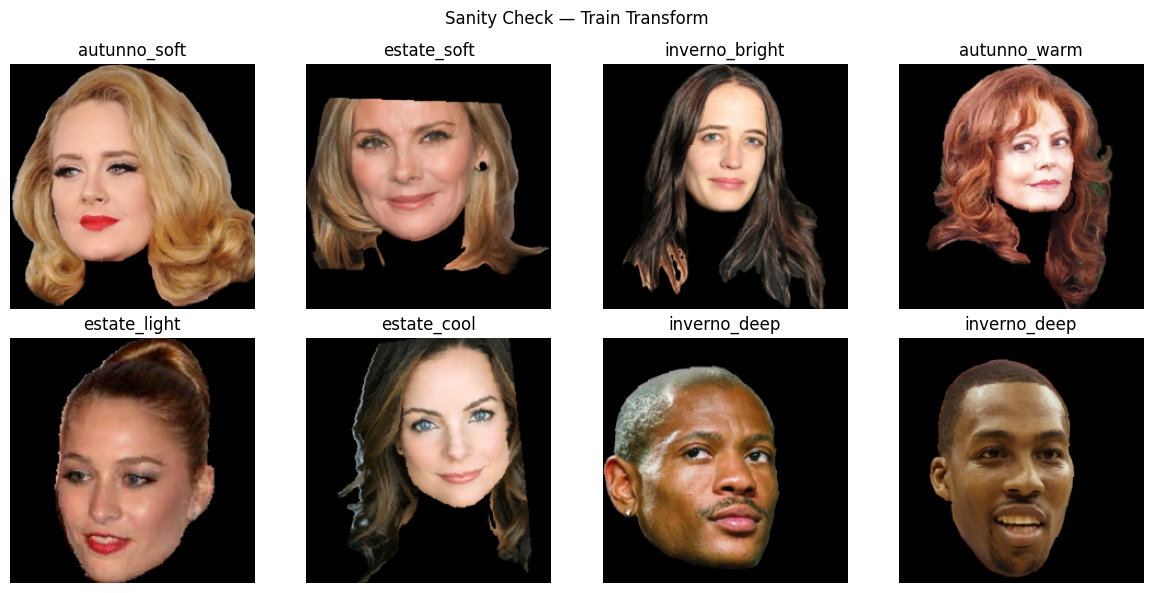

In [21]:
# ============================================================
# 21. VISUAL SANITY CHECK AFTER PREPROCESSING
# ============================================================

def denormalize(img):
    mean = torch.tensor(NORM_MEAN).view(3, 1, 1)
    std = torch.tensor(NORM_STD).view(3, 1, 1)
    return img * std + mean

fig, axes = plt.subplots(
    2,
    4,
    figsize=(12, 6),
)

for i, ax in enumerate(axes.flat):
    img = denormalize(
        images[i].cpu()
    ).clamp(0, 1)

    ax.imshow(
        img.permute(1, 2, 0)
    )

    ax.set_title(
        idx2class[
            labels[i].item()
        ]
    )
    ax.axis("off")

plt.suptitle("Sanity Check — Train Transform")
plt.tight_layout()
plt.show()

## 22. Simpan manifest split & mapping

Manifest ini kecil dan berguna untuk:
- reproduksi eksperimen;
- dokumentasi laporan;
- memastikan training session berikutnya menggunakan split yang sama.

File gambar **tidak disalin ulang** pada tahap ini.

In [22]:
# ============================================================
# 22. SAVE SPLIT MANIFESTS & CLASS MAPPING
# ============================================================

ARTIFACT_DIR = Path("/kaggle/working/pretraining_artifacts")
ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)

manifest_cols = [
    SEASON_COL,
    SUBCLASS_COL,
    "joint_label",
    PARTITION_COL,
    MASKED_PATH_COL,
    "md5",
]

train_df[manifest_cols].to_csv(
    ARTIFACT_DIR / "train_split.csv",
    index=False,
)

val_df[manifest_cols].to_csv(
    ARTIFACT_DIR / "val_split.csv",
    index=False,
)

test_df[manifest_cols].to_csv(
    ARTIFACT_DIR / "test_split.csv",
    index=False,
)

with open(
    ARTIFACT_DIR / "class_mapping.json",
    "w",
    encoding="utf-8",
) as f:
    json.dump(
        {
            "class2idx": class2idx,
            "idx2class": {
                str(k): v
                for k, v in idx2class.items()
            },
            "seed": SEED,
            "img_size": IMG_SIZE,
            "batch_size": BATCH_SIZE,
        },
        f,
        indent=2,
    )

print("Saved to:", ARTIFACT_DIR)
for p in sorted(ARTIFACT_DIR.iterdir()):
    print("-", p.name)

Saved to: /kaggle/working/pretraining_artifacts
- class_mapping.json
- test_split.csv
- train_split.csv
- val_split.csv


In [23]:
# ============================================================
# 23. FINAL READINESS SUMMARY
# ============================================================

summary = {
    "mode": MODE,
    "total_annotation": len(df),
    "valid_paths": int(df["resolved_path"].notna().sum()),
    "corrupt_images": len(corrupt_records),
    "season_classes": int(df[SEASON_COL].nunique()),
    "joint_classes": int(df["joint_label"].nunique()),
    "official_train": int((df[PARTITION_COL] == "train").sum()),
    "official_test": int((df[PARTITION_COL] == "test").sum()),
    "internal_train": len(train_df),
    "internal_val": len(val_df),
    "final_test": len(test_df),
    "official_cross_split_duplicate_hashes": len(cross_official_hashes),
    "train_val_overlap": train_val_overlap,
    "train_test_overlap": train_test_overlap,
    "val_test_overlap": val_test_overlap,
    "imbalance_ratio": round(
        float(clean_joint_counts.max() / clean_joint_counts.min()),
        3,
    ),
    "batch_shape": list(images.shape),
}

display(
    pd.DataFrame(
        summary.items(),
        columns=["Metric", "Value"],
    )
)

checks = {
    "4920 image path valid": int(df["resolved_path"].notna().sum()) == len(df),
    "0 corrupt image": len(corrupt_records) == 0,
    "4 season": df[SEASON_COL].nunique() == 4,
    "12 joint classes": df["joint_label"].nunique() == 12,
    "0 official train-test identical-file leakage": len(cross_official_hashes) == 0,
    "0 train-val leakage": train_val_overlap == 0,
    "0 train-test leakage": train_test_overlap == 0,
    "0 val-test leakage": val_test_overlap == 0,
    "Batch = [B, 3, 224, 224]": tuple(images.shape[1:]) == (3, 224, 224),
    "Label range = 0..11": labels.min().item() >= 0 and labels.max().item() <= 11,
}

all_passed = True

print("\n" + "=" * 72)
print("PRE-TRAINING READINESS")
print("=" * 72)

for name, passed in checks.items():
    status = "PASS" if passed else "FAIL"
    print(f"[{status}] {name}")
    all_passed &= bool(passed)

print("=" * 72)

if all_passed:
    print("✅ DATASET + PREPROCESSING READY FOR EFFICIENTNET TRAINING")
    print("STOP DI SINI. Training model dibuat pada session/notebook berikutnya.")
else:
    print("❌ BELUM READY. Perbaiki semua check yang FAIL sebelum training.")

,Metric,Value
0,mode,ENCRYPTED_SOURCE
1,total_annotation,4920
2,valid_paths,4920
3,corrupt_images,0
4,season_classes,4
5,joint_classes,12
6,official_train,4008
7,official_test,912
8,internal_train,3406
9,internal_val,602



PRE-TRAINING READINESS
[PASS] 4920 image path valid
[PASS] 0 corrupt image
[PASS] 4 season
[PASS] 12 joint classes
[PASS] 0 official train-test identical-file leakage
[PASS] 0 train-val leakage
[PASS] 0 train-test leakage
[PASS] 0 val-test leakage
[PASS] Batch = [B, 3, 224, 224]
[PASS] Label range = 0..11
✅ DATASET + PREPROCESSING READY FOR EFFICIENTNET TRAINING
STOP DI SINI. Training model dibuat pada session/notebook berikutnya.


# Training EfficientNet-B0

Mulai dari bagian ini, aktifkan **GPU T4**.

Baseline:
- EfficientNet-B0 pretrained ImageNet
- 12 joint classes
- CrossEntropyLoss tanpa class weighting
- AdamW
- AMP / mixed precision
- stage 1: classifier head
- stage 2: fine-tuning seluruh network
- early stopping berdasarkan **validation Macro F1**
- best checkpoint disimpan ke `/kaggle/working/best_efficientnet_b0_rgbm.pth`

Metric final:
- Accuracy
- Macro Precision
- Macro Recall
- Macro F1
- Weighted F1
- Top-3 Accuracy
- Recall per class
- Confusion Matrix 12×12

## 24. GPU / environment check

Untuk training:
- Kaggle Settings → Accelerator → **GPU T4**
- pastikan `torch.cuda.is_available()` bernilai `True`.

Jika `False`, **jangan training** karena proses akan jatuh ke CPU dan jauh lebih lambat.

In [24]:
# ============================================================
# 24. DEVICE / CUDA CHECK
# ============================================================

import torch
import torchvision

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("PyTorch     :", torch.__version__)
print("Torchvision :", torchvision.__version__)
print("Device      :", DEVICE)

if torch.cuda.is_available():
    print("GPU         :", torch.cuda.get_device_name(0))
    print(
        "VRAM total  :",
        round(
            torch.cuda.get_device_properties(0).total_memory / (1024**3),
            2
        ),
        "GiB"
    )

assert DEVICE.type == "cuda", (
    "GPU belum aktif. Kaggle Settings -> Accelerator -> GPU T4, "
    "lalu restart/run kembali."
)

PyTorch     : 2.11.0+cu128
Torchvision : 0.26.0+cu128
Device      : cuda
GPU         : Tesla T4
VRAM total  : 14.56 GiB


## 25. EfficientNet-B0 baseline

Stage 1 melatih classifier head dengan backbone dibekukan sebentar.  
Stage 2 membuka seluruh backbone dan melakukan fine-tuning dengan learning rate lebih kecil.

In [25]:
# ============================================================
# 25. BUILD EFFICIENTNET-B0
# ============================================================

import torch.nn as nn
from torchvision.models import (
    efficientnet_b0,
    EfficientNet_B0_Weights,
)

NUM_CLASSES = len(class_names)

weights = EfficientNet_B0_Weights.DEFAULT

model = efficientnet_b0(
    weights=weights
)

# Freeze feature extractor untuk stage 1
for param in model.features.parameters():
    param.requires_grad = False

in_features = model.classifier[1].in_features

model.classifier = nn.Sequential(
    nn.Dropout(p=0.25),
    nn.Linear(
        in_features,
        NUM_CLASSES
    )
)

model = model.to(DEVICE)

trainable_params = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

total_params = sum(
    p.numel()
    for p in model.parameters()
)

print("Classes          :", NUM_CLASSES)
print("Total params     :", f"{total_params:,}")
print("Trainable stage1 :", f"{trainable_params:,}")
print(model.classifier)

Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 123MB/s] 


Classes          : 12
Total params     : 4,022,920
Trainable stage1 : 15,372
Sequential(
  (0): Dropout(p=0.25, inplace=False)
  (1): Linear(in_features=1280, out_features=12, bias=True)
)


In [26]:
# ============================================================
# 26. ONE-BATCH GPU FORWARD SANITY CHECK
# ============================================================

model.eval()

sample_images, sample_labels = next(
    iter(train_loader)
)

sample_images = sample_images.to(
    DEVICE,
    non_blocking=True
)

with torch.no_grad():
    sample_logits = model(
        sample_images
    )

print("Input :", sample_images.shape)
print("Output:", sample_logits.shape)

assert sample_logits.shape == (
    sample_images.shape[0],
    NUM_CLASSES,
)

print("✅ GPU forward pass PASS.")

Input : torch.Size([32, 3, 224, 224])
Output: torch.Size([32, 12])
✅ GPU forward pass PASS.


## 27. Training utilities

Best model dipilih berdasarkan **validation Macro F1**, bukan hanya accuracy.  
Hal ini lebih sesuai karena kita ingin performa antarkelas tetap seimbang.

In [27]:
# ============================================================
# 27. METRICS + TRAIN / EVAL FUNCTIONS
# ============================================================

import time
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
)

criterion = nn.CrossEntropyLoss()

USE_AMP = DEVICE.type == "cuda"

# Compatibility-friendly AMP scaler
try:
    scaler = torch.amp.GradScaler(
        "cuda",
        enabled=USE_AMP
    )
except Exception:
    scaler = torch.cuda.amp.GradScaler(
        enabled=USE_AMP
    )


def autocast_context():
    if USE_AMP:
        try:
            return torch.amp.autocast(
                device_type="cuda",
                dtype=torch.float16
            )
        except Exception:
            return torch.cuda.amp.autocast()

    from contextlib import nullcontext
    return nullcontext()


def classification_metrics(
    y_true,
    y_pred
):
    accuracy = accuracy_score(
        y_true,
        y_pred
    )

    precision, recall, f1, _ = (
        precision_recall_fscore_support(
            y_true,
            y_pred,
            average="macro",
            zero_division=0,
        )
    )

    return {
        "accuracy": float(accuracy),
        "macro_precision": float(precision),
        "macro_recall": float(recall),
        "macro_f1": float(f1),
    }


def train_one_epoch(
    model,
    loader,
    optimizer,
    criterion,
):
    model.train()

    running_loss = 0.0
    y_true = []
    y_pred = []

    for images_batch, labels_batch in loader:

        images_batch = images_batch.to(
            DEVICE,
            non_blocking=True,
        )
        labels_batch = labels_batch.to(
            DEVICE,
            non_blocking=True,
        )

        optimizer.zero_grad(
            set_to_none=True
        )

        with autocast_context():
            logits = model(
                images_batch
            )
            loss = criterion(
                logits,
                labels_batch
            )

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        running_loss += (
            loss.item()
            * images_batch.size(0)
        )

        preds = logits.argmax(
            dim=1
        )

        y_true.extend(
            labels_batch
            .detach()
            .cpu()
            .tolist()
        )
        y_pred.extend(
            preds
            .detach()
            .cpu()
            .tolist()
        )

    epoch_loss = (
        running_loss
        / len(loader.dataset)
    )

    metrics = classification_metrics(
        y_true,
        y_pred,
    )

    metrics["loss"] = epoch_loss

    return metrics


@torch.no_grad()
def evaluate_loader(
    model,
    loader,
    criterion,
    return_probs=False,
):
    model.eval()

    running_loss = 0.0
    y_true = []
    y_pred = []
    prob_list = []

    for images_batch, labels_batch in loader:

        images_batch = images_batch.to(
            DEVICE,
            non_blocking=True,
        )
        labels_batch = labels_batch.to(
            DEVICE,
            non_blocking=True,
        )

        with autocast_context():
            logits = model(
                images_batch
            )
            loss = criterion(
                logits,
                labels_batch
            )

        probs = torch.softmax(
            logits,
            dim=1
        )

        preds = probs.argmax(
            dim=1
        )

        running_loss += (
            loss.item()
            * images_batch.size(0)
        )

        y_true.extend(
            labels_batch
            .cpu()
            .tolist()
        )
        y_pred.extend(
            preds
            .cpu()
            .tolist()
        )

        if return_probs:
            prob_list.append(
                probs.cpu()
            )

    metrics = classification_metrics(
        y_true,
        y_pred,
    )

    metrics["loss"] = (
        running_loss
        / len(loader.dataset)
    )

    if return_probs:
        probs_all = torch.cat(
            prob_list,
            dim=0
        ).numpy()

        return (
            metrics,
            np.array(y_true),
            np.array(y_pred),
            probs_all,
        )

    return metrics

## 28. Stage 1 — train classifier head

Backbone dibekukan selama 3 epoch. Ini memberi classifier kesempatan menyesuaikan diri dengan 12 kelas baru tanpa langsung mengubah feature extractor pretrained.

In [28]:
# ============================================================
# 28. STAGE 1 — CLASSIFIER HEAD
# ============================================================

STAGE1_EPOCHS = 3
HEAD_LR = 1e-3
WEIGHT_DECAY = 1e-4

optimizer = torch.optim.AdamW(
    filter(
        lambda p: p.requires_grad,
        model.parameters()
    ),
    lr=HEAD_LR,
    weight_decay=WEIGHT_DECAY,
)

history = []

print("STAGE 1 — classifier head")
print("=" * 80)

for epoch in range(
    1,
    STAGE1_EPOCHS + 1
):

    start = time.time()

    train_metrics = train_one_epoch(
        model,
        train_loader,
        optimizer,
        criterion,
    )

    val_metrics = evaluate_loader(
        model,
        val_loader,
        criterion,
    )

    elapsed = time.time() - start

    row = {
        "stage": 1,
        "epoch": epoch,
        "train_loss": train_metrics["loss"],
        "train_acc": train_metrics["accuracy"],
        "train_macro_recall": train_metrics["macro_recall"],
        "train_macro_f1": train_metrics["macro_f1"],
        "val_loss": val_metrics["loss"],
        "val_acc": val_metrics["accuracy"],
        "val_macro_recall": val_metrics["macro_recall"],
        "val_macro_f1": val_metrics["macro_f1"],
        "seconds": elapsed,
    }

    history.append(row)

    print(
        f"Epoch {epoch:02d}/{STAGE1_EPOCHS} | "
        f"{elapsed:6.1f}s | "
        f"train loss {train_metrics['loss']:.4f} "
        f"acc {train_metrics['accuracy']:.4f} "
        f"F1 {train_metrics['macro_f1']:.4f} | "
        f"val loss {val_metrics['loss']:.4f} "
        f"acc {val_metrics['accuracy']:.4f} "
        f"recall {val_metrics['macro_recall']:.4f} "
        f"F1 {val_metrics['macro_f1']:.4f}"
    )

STAGE 1 — classifier head
Epoch 01/3 |   37.6s | train loss 2.2580 acc 0.2032 F1 0.1755 | val loss 2.0885 acc 0.2757 recall 0.2579 F1 0.2324
Epoch 02/3 |   23.3s | train loss 2.0199 acc 0.2962 F1 0.2699 | val loss 1.9994 acc 0.3140 recall 0.2909 F1 0.2686
Epoch 03/3 |   23.1s | train loss 1.9435 acc 0.3282 F1 0.3071 | val loss 1.9513 acc 0.3106 recall 0.2932 F1 0.2816


## 29. Stage 2 — full fine-tuning

Seluruh EfficientNet dibuka. Backbone memakai LR lebih kecil daripada classifier.  
Early stopping berdasarkan `val_macro_f1`.

In [29]:
# ============================================================
# 29. STAGE 2 — FULL FINE-TUNING
# ============================================================

for param in model.features.parameters():
    param.requires_grad = True

BACKBONE_LR = 1e-4
CLASSIFIER_LR = 5e-4
MAX_FINETUNE_EPOCHS = 25
EARLY_STOPPING_PATIENCE = 5

optimizer = torch.optim.AdamW(
    [
        {
            "params": model.features.parameters(),
            "lr": BACKBONE_LR,
        },
        {
            "params": model.classifier.parameters(),
            "lr": CLASSIFIER_LR,
        },
    ],
    weight_decay=WEIGHT_DECAY,
)

scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer,
    T_max=MAX_FINETUNE_EPOCHS,
)

BEST_MODEL_PATH = Path(
    "/kaggle/working/best_efficientnet_b0_rgbm.pth"
)

best_val_f1 = -1.0
best_epoch = None
epochs_without_improvement = 0

print("STAGE 2 — full fine-tuning")
print("=" * 90)

for epoch in range(
    1,
    MAX_FINETUNE_EPOCHS + 1
):

    start = time.time()

    train_metrics = train_one_epoch(
        model,
        train_loader,
        optimizer,
        criterion,
    )

    val_metrics = evaluate_loader(
        model,
        val_loader,
        criterion,
    )

    scheduler.step()

    elapsed = time.time() - start

    global_epoch = (
        STAGE1_EPOCHS
        + epoch
    )

    row = {
        "stage": 2,
        "epoch": global_epoch,
        "train_loss": train_metrics["loss"],
        "train_acc": train_metrics["accuracy"],
        "train_macro_recall": train_metrics["macro_recall"],
        "train_macro_f1": train_metrics["macro_f1"],
        "val_loss": val_metrics["loss"],
        "val_acc": val_metrics["accuracy"],
        "val_macro_recall": val_metrics["macro_recall"],
        "val_macro_f1": val_metrics["macro_f1"],
        "seconds": elapsed,
        "backbone_lr": optimizer.param_groups[0]["lr"],
        "classifier_lr": optimizer.param_groups[1]["lr"],
    }

    history.append(row)

    improved = (
        val_metrics["macro_f1"]
        > best_val_f1 + 1e-4
    )

    if improved:
        best_val_f1 = (
            val_metrics["macro_f1"]
        )
        best_epoch = global_epoch
        epochs_without_improvement = 0

        torch.save(
            {
                "model_state_dict": model.state_dict(),
                "class2idx": class2idx,
                "idx2class": idx2class,
                "best_epoch": best_epoch,
                "best_val_macro_f1": best_val_f1,
                "img_size": IMG_SIZE,
                "norm_mean": NORM_MEAN,
                "norm_std": NORM_STD,
                "seed": SEED,
            },
            BEST_MODEL_PATH,
        )

        marker = "✅ BEST"

    else:
        epochs_without_improvement += 1
        marker = ""

    print(
        f"Epoch {global_epoch:02d} | "
        f"{elapsed:6.1f}s | "
        f"train loss {train_metrics['loss']:.4f} "
        f"acc {train_metrics['accuracy']:.4f} "
        f"F1 {train_metrics['macro_f1']:.4f} | "
        f"val loss {val_metrics['loss']:.4f} "
        f"acc {val_metrics['accuracy']:.4f} "
        f"recall {val_metrics['macro_recall']:.4f} "
        f"F1 {val_metrics['macro_f1']:.4f} "
        f"{marker}"
    )

    if (
        epochs_without_improvement
        >= EARLY_STOPPING_PATIENCE
    ):
        print(
            f"\nEarly stopping. "
            f"Tidak ada peningkatan Macro F1 selama "
            f"{EARLY_STOPPING_PATIENCE} epoch."
        )
        break

print("\nBest epoch        :", best_epoch)
print("Best val Macro F1 :", round(best_val_f1, 4))
print("Best model        :", BEST_MODEL_PATH)

STAGE 2 — full fine-tuning
Epoch 04 |   40.7s | train loss 1.8376 acc 0.3594 F1 0.3399 | val loss 1.8402 acc 0.3555 recall 0.3449 F1 0.3383 ✅ BEST
Epoch 05 |   25.5s | train loss 1.6098 acc 0.4375 F1 0.4221 | val loss 1.7814 acc 0.3671 recall 0.3607 F1 0.3565 ✅ BEST
Epoch 06 |   25.2s | train loss 1.4305 acc 0.5065 F1 0.4958 | val loss 1.7939 acc 0.3854 recall 0.3812 F1 0.3782 ✅ BEST
Epoch 07 |   26.0s | train loss 1.2221 acc 0.5875 F1 0.5817 | val loss 1.8071 acc 0.3970 recall 0.3925 F1 0.3865 ✅ BEST
Epoch 08 |   25.7s | train loss 1.0446 acc 0.6512 F1 0.6435 | val loss 1.8478 acc 0.3953 recall 0.3852 F1 0.3823 
Epoch 09 |   25.8s | train loss 0.8840 acc 0.7079 F1 0.7042 | val loss 1.9064 acc 0.4070 recall 0.4026 F1 0.3979 ✅ BEST
Epoch 10 |   26.8s | train loss 0.7391 acc 0.7616 F1 0.7590 | val loss 1.9464 acc 0.4086 recall 0.4035 F1 0.4055 ✅ BEST
Epoch 11 |   26.4s | train loss 0.5800 acc 0.8194 F1 0.8175 | val loss 2.0550 acc 0.3854 recall 0.3820 F1 0.3795 
Epoch 12 |   27.4s | trai

## 30. Training curves

,stage,epoch,train_loss,train_acc,train_macro_recall,train_macro_f1,val_loss,val_acc,val_macro_recall,val_macro_f1,seconds,backbone_lr,classifier_lr
10,2,11,0.580000,0.819436,0.815805,0.817506,2.054984,0.385382,0.381973,0.379475,26.395022,0.000077,0.000384
11,2,12,0.487034,0.852319,0.850089,0.851814,2.173668,0.397010,0.393793,0.391349,27.353808,0.000071,0.000356
12,2,13,0.413713,0.880211,0.878910,0.879353,2.241150,0.383721,0.380486,0.385348,26.436774,0.000065,0.000327
13,2,14,0.360557,0.898121,0.897857,0.897879,2.242112,0.403654,0.400301,0.403605,26.593268,0.000059,0.000297
14,2,15,0.309359,0.908984,0.907131,0.908070,2.328352,0.413621,0.409548,0.407371,25.561400,0.000053,0.000266
15,2,16,0.263628,0.931591,0.931374,0.932246,2.411162,0.403654,0.402059,0.401683,26.401525,0.000047,0.000234
16,2,17,0.218323,0.943629,0.942065,0.942606,2.448399,0.403654,0.400012,0.398347,26.273426,0.000041,0.000203
17,2,18,0.221519,0.939518,0.939286,0.939286,2.447583,0.401993,0.397645,0.395454,26.189530,0.000035,0.000173
18,2,19,0.193302,0.950088,0.949149,0.949435,2.500158,0.406977,0.402584,0.404928,26.341981,0.000029,0.000144
19,2,20,0.173722,0.955666,0.955568,0.955720,2.525015,0.405316,0.402170,0.400092,26.199797,0.000023,0.000116


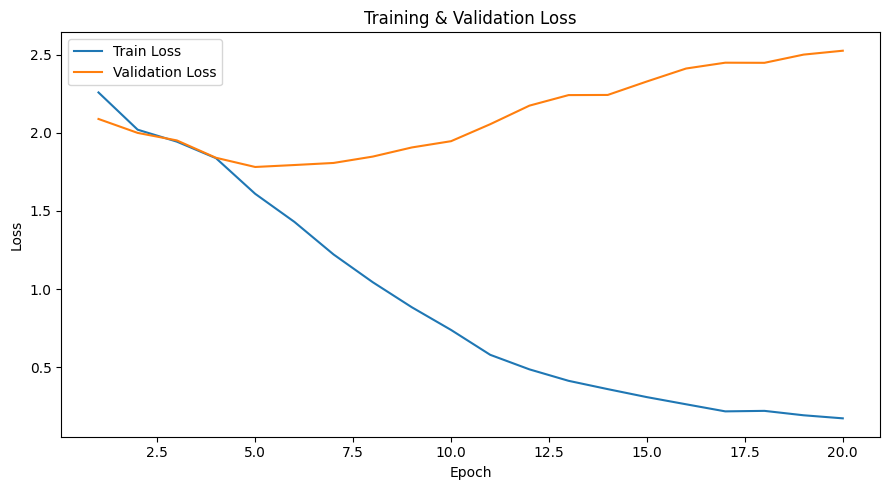

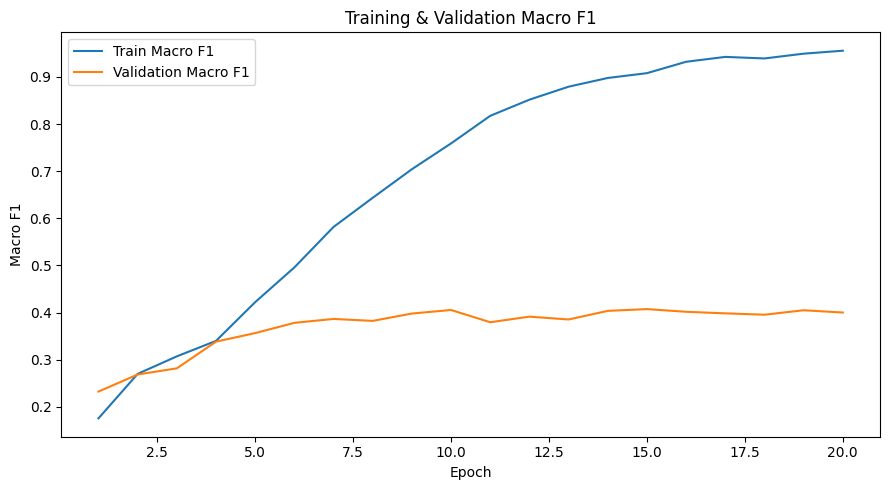

In [30]:
# ============================================================
# 30. TRAINING HISTORY & CURVES
# ============================================================

history_df = pd.DataFrame(history)

HISTORY_PATH = Path(
    "/kaggle/working/training_history_rgbm.csv"
)

history_df.to_csv(
    HISTORY_PATH,
    index=False,
)

display(
    history_df.tail(10)
)

plt.figure(figsize=(9, 5))
plt.plot(
    history_df["epoch"],
    history_df["train_loss"],
    label="Train Loss",
)
plt.plot(
    history_df["epoch"],
    history_df["val_loss"],
    label="Validation Loss",
)
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training & Validation Loss")
plt.legend()
plt.tight_layout()
plt.show()

plt.figure(figsize=(9, 5))
plt.plot(
    history_df["epoch"],
    history_df["train_macro_f1"],
    label="Train Macro F1",
)
plt.plot(
    history_df["epoch"],
    history_df["val_macro_f1"],
    label="Validation Macro F1",
)
plt.xlabel("Epoch")
plt.ylabel("Macro F1")
plt.title("Training & Validation Macro F1")
plt.legend()
plt.tight_layout()
plt.show()

## 31. Final evaluation — official test

Test set baru dipakai **setelah best model ditentukan dari validation**.

In [31]:
# ============================================================
# 31. LOAD BEST CHECKPOINT + OFFICIAL TEST
# ============================================================

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    precision_recall_fscore_support,
)

checkpoint = torch.load(
    BEST_MODEL_PATH,
    map_location=DEVICE,
)

model.load_state_dict(
    checkpoint["model_state_dict"]
)

model.eval()

(
    test_metrics,
    y_true,
    y_pred,
    y_probs,
) = evaluate_loader(
    model,
    test_loader,
    criterion,
    return_probs=True,
)

# Weighted F1
_, _, weighted_f1, _ = (
    precision_recall_fscore_support(
        y_true,
        y_pred,
        average="weighted",
        zero_division=0,
    )
)

# Top-3 accuracy
top3_indices = np.argsort(
    y_probs,
    axis=1,
)[:, -3:]

top3_correct = np.array([
    true_label in row
    for true_label, row in zip(
        y_true,
        top3_indices,
    )
])

top3_accuracy = float(
    top3_correct.mean()
)

final_metrics = {
    "test_loss": test_metrics["loss"],
    "accuracy": test_metrics["accuracy"],
    "macro_precision": test_metrics["macro_precision"],
    "macro_recall": test_metrics["macro_recall"],
    "macro_f1": test_metrics["macro_f1"],
    "weighted_f1": float(weighted_f1),
    "top3_accuracy": top3_accuracy,
}

print("=" * 70)
print("OFFICIAL TEST RESULTS")
print("=" * 70)

for key, value in final_metrics.items():
    print(
        f"{key:18s}: {value:.4f}"
    )

OFFICIAL TEST RESULTS
test_loss         : 2.8327
accuracy          : 0.2895
macro_precision   : 0.2638
macro_recall      : 0.2658
macro_f1          : 0.2604
weighted_f1       : 0.2825
top3_accuracy     : 0.5987


In [32]:
# ============================================================
# 32. CLASSIFICATION REPORT + PER-CLASS RECALL
# ============================================================

target_names = [
    idx2class[i]
    for i in range(NUM_CLASSES)
]

report_dict = classification_report(
    y_true,
    y_pred,
    target_names=target_names,
    output_dict=True,
    zero_division=0,
)

report_df = pd.DataFrame(
    report_dict
).T

display(
    report_df.loc[
        target_names,
        [
            "precision",
            "recall",
            "f1-score",
            "support",
        ]
    ].sort_values(
        "recall",
        ascending=False,
    )
)

REPORT_PATH = Path(
    "/kaggle/working/classification_report_rgbm.csv"
)

report_df.to_csv(
    REPORT_PATH
)

print(
    "Classification report saved:",
    REPORT_PATH
)

,precision,recall,f1-score,support
inverno_deep,0.417722,0.564103,0.480000,117.0
autunno_deep,0.473118,0.392857,0.429268,112.0
primavera_light,0.271739,0.390625,0.320513,64.0
autunno_warm,0.302632,0.310811,0.306667,74.0
primavera_warm,0.293333,0.301370,0.297297,73.0
estate_cool,0.187500,0.226415,0.205128,53.0
inverno_cool,0.277778,0.224719,0.248447,89.0
autunno_soft,0.174419,0.205479,0.188679,73.0
estate_light,0.226415,0.171429,0.195122,70.0
inverno_bright,0.204545,0.155172,0.176471,58.0


Classification report saved: /kaggle/working/classification_report_rgbm.csv


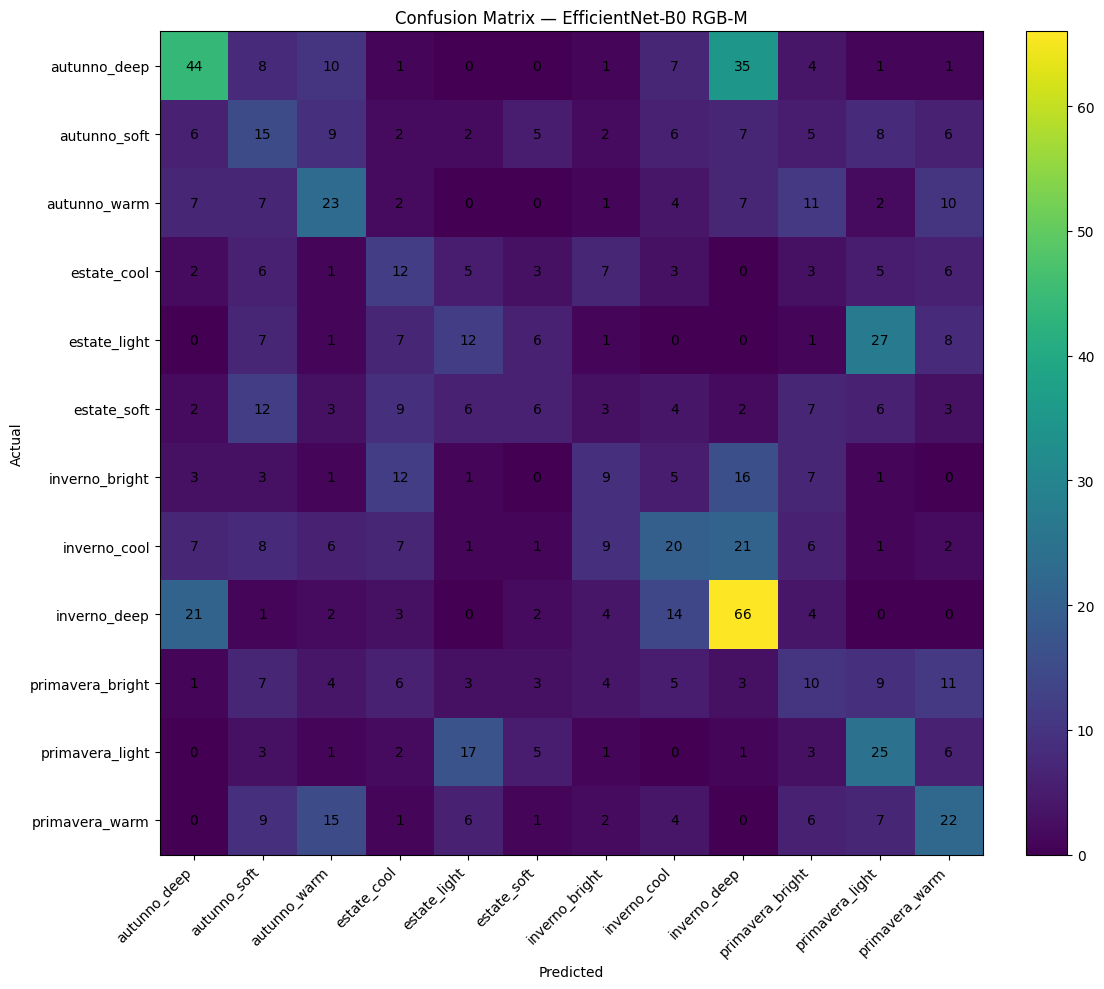

Saved: /kaggle/working/confusion_matrix_rgbm.png


In [33]:
# ============================================================
# 33. CONFUSION MATRIX
# ============================================================

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=list(range(NUM_CLASSES)),
)

fig, ax = plt.subplots(
    figsize=(12, 10)
)

im = ax.imshow(cm)

ax.set_xticks(
    np.arange(NUM_CLASSES)
)
ax.set_yticks(
    np.arange(NUM_CLASSES)
)

ax.set_xticklabels(
    target_names,
    rotation=45,
    ha="right",
)
ax.set_yticklabels(
    target_names
)

ax.set_xlabel("Predicted")
ax.set_ylabel("Actual")
ax.set_title(
    "Confusion Matrix — EfficientNet-B0 RGB-M"
)

# Cell labels
threshold = cm.max() / 2 if cm.max() > 0 else 0

for i in range(NUM_CLASSES):
    for j in range(NUM_CLASSES):
        ax.text(
            j,
            i,
            str(cm[i, j]),
            ha="center",
            va="center",
        )

fig.colorbar(
    im,
    ax=ax,
    fraction=0.046,
    pad=0.04,
)

plt.tight_layout()

CM_PATH = Path(
    "/kaggle/working/confusion_matrix_rgbm.png"
)

plt.savefig(
    CM_PATH,
    dpi=160,
    bbox_inches="tight",
)

plt.show()

print("Saved:", CM_PATH)

In [34]:
# ============================================================
# 34. SAVE FINAL METRICS / TRAINING CONFIG
# ============================================================

FINAL_METRICS_PATH = Path(
    "/kaggle/working/final_metrics_rgbm.json"
)

final_payload = {
    **final_metrics,
    "best_epoch": checkpoint["best_epoch"],
    "best_val_macro_f1": checkpoint["best_val_macro_f1"],
    "num_classes": NUM_CLASSES,
    "class2idx": class2idx,
    "img_size": IMG_SIZE,
    "batch_size": BATCH_SIZE,
    "stage1_epochs": STAGE1_EPOCHS,
    "max_finetune_epochs": MAX_FINETUNE_EPOCHS,
    "early_stopping_patience": EARLY_STOPPING_PATIENCE,
    "head_lr": HEAD_LR,
    "backbone_lr": BACKBONE_LR,
    "classifier_lr": CLASSIFIER_LR,
    "weight_decay": WEIGHT_DECAY,
    "seed": SEED,
}

with open(
    FINAL_METRICS_PATH,
    "w",
    encoding="utf-8",
) as f:
    json.dump(
        final_payload,
        f,
        indent=2,
    )

print("Artifacts:")
for path in [
    BEST_MODEL_PATH,
    HISTORY_PATH,
    REPORT_PATH,
    CM_PATH,
    FINAL_METRICS_PATH,
]:
    print("-", path)

print("\n✅ BASELINE TRAINING + OFFICIAL TEST EVALUATION SELESAI")

Artifacts:
- /kaggle/working/best_efficientnet_b0_rgbm.pth
- /kaggle/working/training_history_rgbm.csv
- /kaggle/working/classification_report_rgbm.csv
- /kaggle/working/confusion_matrix_rgbm.png
- /kaggle/working/final_metrics_rgbm.json

✅ BASELINE TRAINING + OFFICIAL TEST EVALUATION SELESAI


In [35]:
import modellab_registry

# 1. Ekstrak hasil evaluasi yang sudah dihitung oleh notebook Anda di sel sebelumnya
# dan simpan ke variabel dengan nama standar yang akan dipindai oleh globals()
accuracy = final_metrics["accuracy"]
f1_score = final_metrics["macro_f1"]
precision = final_metrics["macro_precision"]
recall = final_metrics["macro_recall"]

# 2. Panggil fungsi auto-log, sertakan globals()
modellab_registry.auto_log_experiment(
    env_globals=globals(),
    topic="topic-a",
    model="EfficientNet-B0",
    objective="Pembangunan Baseline CNN RGB-M",
    dataset="deep_armocromia",
    owner="Fatih Itsbatul Haq"
)

===REGISTRY_PAYLOAD_START===
{"topic": "topic-a", "model": "EfficientNet-B0", "objective": "Pembangunan Baseline CNN RGB-M", "dataset": "deep_armocromia", "owner": "Fatih Itsbatul Haq", "metrics": {"accuracy": 0.2894736842105263, "f1": 0.26035700010983287, "precision": 0.26382954199416836, "recall": 0.26581110502309585}}
===REGISTRY_PAYLOAD_END===
